# AICE Professional 주피터라이트 실전 모의고사 13회 — 공개데이터(대기질 센서 CO 보정 · 영문 백과 주제(NLTK) · 목초지 잡초)

## [ 필독 ] AICE Professional 모의고사 유의사항

- 공식 샘플문항(가공식품 카테고리 분류)과 **같은 시험지 형식**으로 만든 모의고사입니다. 3문항, 180분 기준입니다.
- 공식 시험과 같은 **Tabular / Text / Image 3유형**입니다. 2번 Text 문항은 공식 샘플(상품명 → 카테고리)과 같은 텍스트 분류입니다.
- 본인 스스로 모델을 만들고 **달성 목표 이상의 성능**이 나오도록 개발해야 합니다. 정답(테스트 라벨)은 제공되지 않습니다.
  대신 이 노트북 **맨 마지막 셀**(전체 자동 채점, 정답 키 인코딩)로 제출 파일을 스스로 채점할 수 있습니다(연습용).

## 사용할 수 있는 라이브러리 (주피터라이트 판)

이 모의고사는 **브라우저 주피터라이트(Pyodide · Python 3.14)** 에서 설치 없이 끝까지 풀 수 있도록 라이브러리를 제한했습니다.
필요한 라이브러리는 주피터라이트에 **미리 설치**되어 있습니다. 맨 위 '브라우저 실습' 셀은 확인만 하고 바로 끝납니다(Colab·로컬 Jupyter 에서는 아무 일도 하지 않습니다).

| 구분 | 쓸 수 있음 | 쓰지 않음(브라우저에서 안 됨) |
|---|---|---|
| 데이터·그림 | numpy · pandas · matplotlib · seaborn · Pillow | — |
| 머신러닝 | scikit-learn · LightGBM · XGBoost · imbalanced-learn · joblib | CatBoost |
| 텍스트 | scikit-learn 의 CountVectorizer · TfidfVectorizer · 내장 영어 불용어, **NLTK**(불용어·토큰화·어간 추출, 데이터는 `/drive/nltk_data` 에 미리 들어 있음) | 형태소 분석기 · BERT 등 사전학습 언어 모델 |
| 딥러닝 | `tensorflow.keras` 문법(TensorFlow.js 로 실행되는 대체 구현체, 미리 설치): `Sequential`·함수형(`Input` → 층 → `Model`) · Dense · Dropout · BatchNormalization · Conv2D · MaxPooling2D · GlobalAveragePooling2D · Embedding · LSTM · GRU · 콜백 3종(EarlyStopping · ModelCheckpoint · ReduceLROnPlateau) · `load_img` · `img_to_array` · `image_dataset_from_directory` · `ImageDataGenerator` · `model.save` / `load_model` · **MobileNet v1 전이학습**(`alpha=0.25`, 224×224, `weights='imagenet'` 만) | PyTorch · 다른 사전학습 모델(MobileNetV2/V3 · ResNet · EfficientNet 등) · 사용자 정의 층·손실 · GPU |

- 이미지는 64×64 정도로 줄여 작은 CNN 을 직접 학습하거나, MobileNet v1(alpha 0.25)로 특징을 뽑아 분류기를 학습하세요(전이학습). 브라우저 TensorFlow.js 는 CPython TensorFlow 와 수치가 조금 달라 딥러닝 점수가 약간 다르게 나올 수 있습니다.
- 학습이 오래 걸리면 epoch 를 줄이거나 조기 종료(EarlyStopping)를 쓰세요. 최신 Chrome·Edge 를 권장합니다.

## 시간 배분(180분)

| 문항 | 권장 시간 | 먼저 할 일 |
|---|---|---|
| 1. Tabular (30점) | 50분 | `info()`·`describe()` 로 자료형·결측 확인 → 기본 모델로 제출 파일부터 만들기 |
| 2. Text (35점) | 60분 | 라벨 분포·문장 길이 확인 → TF-IDF + 선형 모델로 기준 점수 |
| 3. Image (35점) | 60분 | 압축 풀기·폴더 구조 확인 → 작은 CNN 으로 기준 점수 |
| 마무리 | 10분 | 제출 파일 6개 이름·열 구조 확인 → 맨 마지막 채점 셀 실행 |

## 시험 자원 가이드

| 구분 | 공식 시험 | 이 모의고사 |
|---|---|---|
| IDE | CPU 8 core · Memory 32G · GPU 1개(VRAM 16GB) | **브라우저 주피터라이트**(설치 없음, CPU) — Colab·로컬 Jupyter 에서도 그대로 실행됨 |
| SW | Python 3.10 · TensorFlow 2.13 · PyTorch 2.1 | Python 3.14(Pyodide) · scikit-learn · LightGBM · XGBoost · Keras 문법(TensorFlow.js) — 위 표의 라이브러리만 |

## 유의 사항

- 막히면 문항 아래 접혀 있는 **힌트 1·2·3단계**를 순서대로 펼쳐 보세요. 단계가 올라갈수록 정답에 가까워집니다.
- 제출 파일명은 **고정**입니다: `answer_1~3` 모델 파일과 `answer_1~3.csv`.


문제에 제시되는 가이드는 필수적으로 준수하여 주시기 바랍니다. 이를 준수하지 않을 경우 채점 제한 또는 0점 처리될 수 있으니
각별히 유의해 주시기 바랍니다.

#### **[학습 정보]**
- 학습 목표 : Tabular · Text · Image 예측 모델 3종을 만들어 달성 목표 이상의 예측 파일을 제출하고, 제출한 코드로 같은 모델이 재현되게 할 수 있다
- AICE 역량 : PT1·PT2 표 데이터 / PX1·PX2 텍스트 / PI1·PI2 이미지 / PS1 제출 파일 형식·재현성
- 제출 파일 : `answer_1~3` 모델 파일(.pkl · .h5 등)과 `answer_1~3.csv` — **파일명은 고정**입니다(이름을 바꾸면 채점되지 않음)

| 문항 | 문제 | 달성 목표 | 역량 | 기술 | 예상 시간 |
|---|---|---|---|---|---|
| 1. Tabular | 저가 가스 센서 값으로 일산화탄소(CO) 농도 보정 예측 | RMSE 0.463 이하 | PT1 표 데이터 전처리·피처 엔지니어링, PT2 표 데이터 모델 학습·평가 | pandas, scikit-learn(RandomForestRegressor, KFold), LightGBM, joblib | 50분 |
| 2. Text | 영문 백과 항목 요약으로 주제 분류(6종, NLTK 전처리) | 정확도 0.92 이상 | PX1 텍스트 정제·벡터화, PX2 텍스트 분류 모델 학습·평가 | pandas, scikit-learn(PorterStemmer, RegexpTokenizer, TfidfVectorizer, LinearSVC), joblib, NLTK | 60분 |
| 3. Image | 목초지 잡초 사진으로 종류 분류(5종) | 정확도 0.71 이상 | PI1 이미지 로딩·전처리, PI2 이미지 분류 모델(CNN·전이학습) | pandas, scikit-learn(LogisticRegression), Keras(TensorFlow.js), joblib | 60분 |

In [1]:
# (브라우저 실습) 주피터라이트에는 tensorflow(TensorFlow.js 대체 구현체)·scikit-learn·LightGBM 등이 미리 설치되어 있어 이 셀은 확인만 합니다.
# Colab·로컬 Jupyter 에서는 아무 일도 하지 않습니다.
import os, sys, importlib.util
if 'pyodide' in sys.modules:
    os.environ['AICE_IMG_DIR'] = '/tmp/aice_images/' + os.path.basename(os.getcwd())   # 이미지 압축은 메모리 폴더에 풂(빠름)
    if not ('tensorflow' in sys.modules or importlib.util.find_spec('tensorflow')):
        # 미리 설치되지 않은 사이트(패치 전 주피터라이트)에서만: 같은 폴더의 tfjs_keras.py 를 불러옵니다
        sys.path[:0] = [os.getcwd(), '/drive']
        import tfjs_keras
        await tfjs_keras.load()
print('준비 완료 — 다음 셀로 넘어가세요.')

준비 완료 — 다음 셀로 넘어가세요.


## 1. Tabular 문제 - 저가 가스 센서 값으로 일산화탄소(CO) 농도 보정 예측 (30점)

<sub>학습 목표: 저가 가스 센서 값으로 일산화탄소(CO) 농도 보정 예측 모델로 테스트 RMSE 0.463 이하을 달성할 수 있다 | 역량: PT1 표 데이터 전처리·피처 엔지니어링, PT2 표 데이터 모델 학습·평가 | 기술: pandas, scikit-learn(RandomForestRegressor, KFold), LightGBM, joblib | 난이도: 실전 | 예상 시간: 50분</sub>

### 문제 개요

값싼 가스 센서 5개(PT08.S1~S5)의 반응값과 기온·습도로, 비싼 기준 분석기가 잰 **일산화탄소 농도(mg/m³)** 를 예측하는 센서 보정 회귀 문제입니다. 센서 값에 **-200 으로 표시된 결측** 이 섞여 있어 먼저 결측으로 바꿔 처리해야 합니다.

제공된 훈련 데이터셋을 활용해 회귀 모델을 개발하고, 테스트 데이터셋의 'CO_GT' 값을 예측하시기 바랍니다.

### 달성 목표

"01_test_x.csv" 파일의 테스트 데이터셋을 기준으로 **RMSE 0.463 이하**를 달성하는 모델을 개발하시기 바랍니다.

단, 테스트 데이터의 정답(Label 값)은 별도로 제공되지 않습니다.

### 데이터 설명

**데이터 위치 및 폴더 구조** — 문제 파일과 동일한 곳에 위치

- `01_train.csv`: 훈련 데이터셋입니다. 훈련 데이터셋으로 모델을 만드세요.
- `01_test_x.csv`: 테스트 데이터셋입니다. 라벨('CO_GT') 값이 제외되어 있습니다.

**Label 정보**

- 'CO_GT' : 기준 분석기로 잰 시간 평균 CO 농도(mg/m³)

**Data 정보**

- 'id' : 행 번호
- 'Date · Time' : 측정 날짜(일/월/년) · 시각(시.분.초)
- 'PT08_S1_CO · PT08_S2_NMHC · PT08_S3_NOx · PT08_S4_NO2 · PT08_S5_O3' : 저가 센서 5종의 반응값(대상 기체 이름이 붙어 있지만 여러 기체에 함께 반응)
- 'T · RH · AH' : 기온(℃) · 상대습도(%) · 절대습도

**데이터 출처** — Air Quality(UCI 360 · CC BY 4.0) — 이탈리아 도시 도로변 저가 금속산화물 센서 5종 + 기준 분석기, 2004-03 ~ 2005-04 시간별

### 데이터 예시

`01_train.csv`

| id | Date | Time | PT08_S1_CO | PT08_S2_NMHC | PT08_S3_NOx | PT08_S4_NO2 | PT08_S5_O3 | … |
|---|---|---|---|---|---|---|---|---|
| 1 | 17/03/2004 | 17.00.00 | 1247 | 1060 | 1032 | 1525 | 1069 | … |
| 2 | 12/02/2005 | 08.00.00 | 1321 | 1046 | 562 | 1263 | 1610 | … |
| 3 | 23/12/2004 | 14.00.00 | 1336 | 1256 | 567 | 1320 | 1828 | … |

`01_test_x.csv`

| id | Date | Time | PT08_S1_CO | PT08_S2_NMHC | PT08_S3_NOx | PT08_S4_NO2 | PT08_S5_O3 | … |
|---|---|---|---|---|---|---|---|---|
| 1 | 27/04/2004 | 06.00.00 | 1120 | 935 | 843 | 1593 | 1126 | … |
| 2 | 09/02/2005 | 02.00.00 | -200 | -200 | -200 | -200 | -200 | … |
| 3 | 24/04/2004 | 03.00.00 | 1022 | 802 | 916 | 1481 | 1078 | … |

### 문제 해결 가이드

(1) 훈련 데이터셋을 이용하여 저가 가스 센서 값으로 일산화탄소(CO) 농도 보정 예측 모델을 만드세요.
- 필요 시 추가로 함수를 만들거나 cell 을 만들어도 됩니다.
- 성능이 가장 좋은 모델을 저장하세요.
- 파일명 : **answer_1.pkl** (또는 다른 확장자의 모델 파일)

(2) 라벨('CO_GT') 값이 제외된 테스트 데이터 파일을 읽어들여 예측값에 대한 컬럼을 추가하여 csv 로 저장하세요.
- 파일명 : **answer_1.csv**
- 테스트 데이터 파일을 읽고 **마지막 컬럼 뒤에 'CO_GT' 컬럼 생성** 후, 모델 예측하여 예측값을 채워주세요.
- 테스트 데이터의 행 순서와 행 수를 바꾸지 마세요. 예측값은 훈련 데이터의 'CO_GT' 와 같은 형식(원래 라벨 이름·단위)이어야 합니다.

(3) 본 문제지를 답안코드 작성된 상태로 저장하세요.
- 파일명 : 시스템매핑번호.ipynb (본 문제지 상단의 저장버튼을 눌러 저장)

### 참고

- 센서·기상 값의 **-200 은 결측** 입니다. `replace(-200, np.nan)` 뒤 중앙값으로 채우거나, 결측을 그대로 다루는 LightGBM 을 쓰세요.
- 시각(Time)에서 **시(hour)**, 날짜에서 **월** 을 뽑으면 교통량 주기를 반영할 수 있습니다.
- 평가 지표는 **RMSE** 입니다.

### 채점 진행 방식 안내

- 1번 문항 배점 : 30점
- 시스템매핑번호.ipynb 실행 가능 여부 확인
- 제출한 코드로 실행했을 때, 제출한 모델 파일과 동일하게 재현되는지 확인
- answer_1.csv 로 제출된 예측 데이터를 정답지와 대조하여, **RMSE 0.5093 이하** 달성
  (공식 샘플의 '목표 70% → 채점 기준 63%' 와 같은 비율)

### 답안 작성

필요한 cell 을 추가하여 작성하세요.

In [ ]:
# 답안 작성

In [2]:

# 1. 라이브러리 및 데이터 불러오기
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

if not Path("01_test_x.csv").exists() and Path("01_test_x(1).csv").exists():
    Path("01_test_x(1).csv").rename("01_test_x.csv")

train_1 = pd.read_csv("01_train.csv")
test_1 = pd.read_csv("01_test_x.csv")

# 2. 데이터 전처리 및 시간 변수 생성
def make_features_1(df):
    X = df.drop(columns=["id", "Date", "Time", "CO_GT"], errors="ignore").copy()
    X = X.replace(-200, np.nan)

    datetime = pd.to_datetime(
        df["Date"] + " " + df["Time"].str.replace(".", ":", regex=False),
        format="%d/%m/%Y %H:%M:%S"
    )

    X["hour"] = datetime.dt.hour
    X["weekday"] = datetime.dt.dayofweek
    X["month"] = datetime.dt.month
    X["dayofyear"] = datetime.dt.dayofyear

    return X

X_1 = make_features_1(train_1)
y_1 = train_1["CO_GT"]
X_test_1 = make_features_1(test_1)

# 3. 학습·검증 데이터 분리
X_train_1, X_valid_1, y_train_1, y_valid_1 = train_test_split(
    X_1, y_1, test_size=0.2, random_state=42
)

# 4. 데이터 확인
print("훈련 원본:", train_1.shape)
print("테스트 원본:", test_1.shape)
print("학습용:", X_train_1.shape)
print("검증용:", X_valid_1.shape)

print("\n결측값 개수:")
print(X_1.isna().sum()[lambda x: x > 0])

print("\n정답 분포:")
print(y_1.describe().round(3))

print("\n입력 변수:")
print(X_1.columns.tolist())


훈련 원본: (6139, 12)
테스트 원본: (1535, 11)
학습용: (4911, 12)
검증용: (1228, 12)

결측값 개수:
PT08_S1_CO      259
PT08_S2_NMHC    259
PT08_S3_NOx     259
PT08_S4_NO2     259
PT08_S5_O3      259
T               259
RH              259
AH              259
dtype: int64

정답 분포:
count    6139.000
mean        2.147
std         1.456
min         0.100
25%         1.100
50%         1.800
75%         2.900
max        11.900
Name: CO_GT, dtype: float64

입력 변수:
['PT08_S1_CO', 'PT08_S2_NMHC', 'PT08_S3_NOx', 'PT08_S4_NO2', 'PT08_S5_O3', 'T', 'RH', 'AH', 'hour', 'weekday', 'month', 'dayofyear']


In [3]:

# 1. 라이브러리 불러오기
from lightgbm import LGBMRegressor, early_stopping, log_evaluation
from sklearn.metrics import mean_squared_error
import numpy as np

# 2. LightGBM 회귀 모델 생성
model_1 = LGBMRegressor(
    n_estimators=1000,
    learning_rate=0.035,
    num_leaves=31,
    random_state=42,
    verbosity=-1
)

# 3. 모델 학습 및 조기 종료
model_1.fit(
    X_train_1,
    y_train_1,
    eval_set=[(X_valid_1, y_valid_1)],
    eval_metric="rmse",
    callbacks=[
        early_stopping(stopping_rounds=60, verbose=False),
        log_evaluation(period=0)
    ]
)

# 4. 검증 데이터 예측 및 성능 평가
pred_valid_1 = model_1.predict(X_valid_1)

rmse_1 = np.sqrt(mean_squared_error(y_valid_1, pred_valid_1))

print(f"검증 RMSE: {rmse_1:.4f}")
print(f"목표 RMSE: 0.4630")
print(f"목표 달성: {'성공' if rmse_1 <= 0.463 else '미달성'}")
print(f"최적 학습 횟수: {model_1.best_iteration_}")


검증 RMSE: 0.3098
목표 RMSE: 0.4630
목표 달성: 성공
최적 학습 횟수: 993


In [4]:

# 1. 최종 모델 생성
final_model_1 = LGBMRegressor(
    n_estimators=model_1.best_iteration_,
    learning_rate=0.035,
    num_leaves=31,
    random_state=42,
    verbosity=-1
)

# 2. 전체 훈련 데이터로 학습
final_model_1.fit(X_1, y_1)

# 3. 모델 저장
import joblib
import os

joblib.dump(final_model_1, "answer_1.pkl")

# 4. 저장 결과 확인
print("최종 학습 데이터:", X_1.shape)
print("학습 트리 수:", final_model_1.n_estimators_)
print("모델 파일:", "answer_1.pkl")
print("파일 크기:", round(os.path.getsize("answer_1.pkl") / 1024, 2), "KB")
print("모델 저장 완료")


최종 학습 데이터: (6139, 12)
학습 트리 수: 993
모델 파일: answer_1.pkl
파일 크기: 2808.39 KB
모델 저장 완료


In [5]:

# 1. 저장된 모델 불러오기
import joblib
import numpy as np
import pandas as pd
import os

loaded_model_1 = joblib.load("answer_1.pkl")

# 2. 저장 전후 예측 결과 비교
pred_before_1 = final_model_1.predict(X_test_1)
pred_after_1 = loaded_model_1.predict(X_test_1)

np.testing.assert_allclose(
    pred_before_1, pred_after_1,
    rtol=1e-12, atol=1e-12
)
print("모델 복원 및 예측값 일치: PASS")

# 3. 테스트 원본에 정답 컬럼 추가
answer_1 = test_1.copy()
answer_1["CO_GT"] = pred_after_1

# 4. 제출 CSV 저장
answer_1.to_csv("answer_1.csv", index=False)

# 5. 저장된 CSV 다시 읽어 검증
check_1 = pd.read_csv("answer_1.csv")

assert os.path.exists("answer_1.pkl")
assert len(check_1) == len(test_1) == 1535
assert check_1.columns.tolist() == test_1.columns.tolist() + ["CO_GT"]
assert check_1["id"].equals(test_1["id"])
assert pd.api.types.is_numeric_dtype(check_1["CO_GT"])
assert check_1["CO_GT"].notna().all()
np.testing.assert_allclose(
    check_1["CO_GT"].to_numpy(),
    pred_after_1,
    rtol=1e-12, atol=1e-12
)

print("제출 파일 검증: PASS")
print("CSV 크기:", check_1.shape)
print("정답 컬럼:", check_1.columns[-1])
print("예측값 범위:", round(check_1["CO_GT"].min(), 3),
      "~", round(check_1["CO_GT"].max(), 3))
print("\n예측 결과 미리보기:")
print(check_1[["id", "CO_GT"]].head())
print("\n제출 파일: answer_1.pkl, answer_1.csv")


모델 복원 및 예측값 일치: PASS
제출 파일 검증: PASS
CSV 크기: (1535, 12)
정답 컬럼: CO_GT
예측값 범위: -0.033 ~ 9.145

예측 결과 미리보기:
   id     CO_GT
0   1  1.522150
1   2  0.889222
2   3  1.078755
3   4  2.515448
4   5  1.768471

제출 파일: answer_1.pkl, answer_1.csv


<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

자료형·결측·정답 분포를 확인합니다. 번호·날짜 원문·누수 열은 빼고 범주형은 원-핫 인코딩합니다. '참고'의 파생 변수를 만든 뒤 선형 모델과 트리 모델(LightGBM 등)을 **교차검증 RMSE** 로 비교해 더 나은 쪽으로 전체 학습하세요.

- 이 문항의 핵심: 센서·기상 값의 **-200 은 결측** 입니다. `replace(-200, np.nan)` 뒤 중앙값으로 채우거나, 결측을 그대로 다루는 LightGBM 을 쓰세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `pandas`, `joblib`, `RandomForestRegressor`, `LGBMRegressor`, `KFold`, `cross_val_score`.

- 참고 문서: <https://joblib.readthedocs.io/en/stable/generated/joblib.dump.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html>
- 참고 문서: <https://lightgbm.readthedocs.io/en/latest/pythonapi/lightgbm.LGBMRegressor.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html>

</details>

<details><summary>힌트 3단계 (코드 구조) - 1번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____
import ____
from sklearn.ensemble import ____
from lightgbm import ____
from sklearn.model_selection import ____, ____

train = pd.read_csv('01_train.csv')
test = pd.read_csv('01_test_x.csv')
LABEL = '____'
print('____', (train == -____).mean().round(____)[lambda s: s > ____].to_dict())

def feats(df):
    d = df.drop(columns=['____', LABEL], errors='____').copy()
    d = d.replace(-____, np.nan)                                     # 결측 표시 -____ → NaN
    d['____'] = d.pop('____').str.slice(____, ____).astype(int)
    d['____'] = pd.to_datetime(d.pop('____'), format='____').dt.month
    return d

# ▷ 후보 모델을 교차검증으로 비교(점수 출력)
# ▷ 학습(검증 데이터·조기 종료)
# ▷ 모델 파일 저장 — answer_N.pkl / .h5
# ▷ 테스트 데이터 예측(행 순서 그대로)
# ▷ 예측 CSV 저장 — answer_N.csv(테스트 열 + 마지막 정답 열)
```
- 제출 파일명: `answer_1.pkl`(모델) · `answer_1.csv`(예측)

</details>

## 2. Text 문제 - 영문 백과 항목 요약으로 주제 분류(6종, NLTK 전처리) (35점)

<sub>학습 목표: 영문 백과 항목 요약으로 주제 분류(6종, NLTK 전처리) 모델로 테스트 정확도 0.92 이상을 달성할 수 있다 | 역량: PX1 텍스트 정제·벡터화, PX2 텍스트 분류 모델 학습·평가 | 기술: pandas, scikit-learn(PorterStemmer, RegexpTokenizer, TfidfVectorizer, LinearSVC), joblib, NLTK | 난이도: 중급 | 예상 시간: 60분</sub>

### 문제 개요

영문 백과사전 항목의 제목과 요약문(평균 약 290자)으로 그 항목의 **주제 6종** 을 분류하는 문제입니다. 영어 문장이므로 **NLTK 로 소문자화·토큰화·불용어 제거·어간 추출(stemming)** 을 한 뒤 TF-IDF 로 벡터화하는 전형적인 흐름을 연습합니다.

제공된 훈련 데이터셋을 활용해 텍스트 다중 분류(6종) 모델을 개발하고, 테스트 데이터셋의 'category' 값을 예측하시기 바랍니다.

### 달성 목표

"02_test_x.csv" 파일의 테스트 데이터셋을 기준으로 **정확도(Accuracy) 92% 이상**을 달성하는 모델을 개발하시기 바랍니다.

단, 테스트 데이터의 정답(Label 값)은 별도로 제공되지 않습니다.

### 데이터 설명

**데이터 위치 및 폴더 구조** — 문제 파일과 동일한 곳에 위치

- `02_train.csv`: 훈련 데이터셋입니다. 훈련 데이터셋으로 모델을 만드세요.
- `02_test_x.csv`: 테스트 데이터셋입니다. 라벨('category') 값이 제외되어 있습니다.

**Label 정보**

- 'category' : Company(회사) / Artist(예술가) / Athlete(운동선수) / Building(건축물) / Animal(동물) / Film(영화)

**Data 정보**

- 'title' : 항목 제목(예: 회사 이름·인물 이름)
- 'text' : 항목 요약문(영어)
- 'id' : 테스트 행 번호(테스트에만)

**데이터 출처** — DBpedia-14(HF fancyzhx/dbpedia_14 · CC BY-SA 3.0 — Wikipedia 기반) 중 6종 — 회사·예술가·운동선수·건축물·동물·영화 각 1,200건

### 데이터 예시

`02_train.csv`

| title | text | category |
|---|---|---|
| Blackspotted nothobranch | The blackspotted nothobranch (Nothobranchius melanospilus) is a species of fish in the Aplocheilidae family. It is found in Kenya and Tanzania. Its natural habitats are intermittent rivers intermittent freshwater lakes and freshwater marshes. | Building |
| SAN Dnevne Novine | SAN Dnevne Novine (English: SAN Daily Newspaper) was a daily newspaper published in Bosnia and Herzegovina. | Film |
| Fonciere des Regions | Foncière des Régions (pronounced: [fɔ̃.sjɛʁ dɛ ʁe.ʒjɔ̃]) is a holding company of real estate investment (REIT) companies that own residential and commercial properties in 8 countries (mostly Europe). Its business comes from the rental and leasing of properties (including hotels and car lots) over 70% of which is office space in France and Italy (in 2009 vacancy rates were at 5.3% in France in other major markets like Rome Italy rental income was lower because office space use was halved). | Company |

`02_test_x.csv`

| id | title | text |
|---|---|---|
| 1 | Wiretap Scars | Wiretap Scars is an album by Sparta released on August 13 2002 on DreamWorks Records and peaked at #71 on the Billboard 200. Only months separated this release from their debut EP Austere. The album is greatly influenced by the music of At the Drive-In with whom most of Sparta's members originally played before their split in 2001.The vocals and track naming in particular reflect At the Drive-In's Relationship of Command the last album made by the group. |
| 2 | Minotaur-class ironclad | The Minotaur-class armoured frigates were enlarged versions of HMS Achilles with heavier armament thicker armour and more powerful engines. The ships of this class were unique among ironclad warships in possessing on completion five masts named fore- second- main- fourth- and mizzen. |
| 3 | Shrine (novel) | Shrine (1983) is a horror novel by James Herbert exploring themes of religious ecstasy mass hysteria demonic possession faith healing and Catholicism. The story is about Alice Pagett a deaf-mute child who's cured one night when she runs to an oak tree behind St. Joseph's her local church. She's found by reporter Gerry Fenn and when news of her cure spreads their village becomes ablaze with publicity. |

### 문제 해결 가이드

(1) 훈련 데이터셋을 이용하여 영문 백과 항목 요약으로 주제 분류(6종, NLTK 전처리) 모델을 만드세요.
- 필요 시 추가로 함수를 만들거나 cell 을 만들어도 됩니다.
- 성능이 가장 좋은 모델을 저장하세요.
- 파일명 : **answer_2.pkl** (또는 다른 확장자의 모델 파일)

(2) 라벨('category') 값이 제외된 테스트 데이터 파일을 읽어들여 예측값에 대한 컬럼을 추가하여 csv 로 저장하세요.
- 파일명 : **answer_2.csv**
- 테스트 데이터 파일을 읽고 **마지막 컬럼 뒤에 'category' 컬럼 생성** 후, 모델 예측하여 예측값을 채워주세요.
- 테스트 데이터의 행 순서와 행 수를 바꾸지 마세요. 예측값은 훈련 데이터의 'category' 와 같은 형식(원래 라벨 이름·단위)이어야 합니다.

(3) 본 문제지를 답안코드 작성된 상태로 저장하세요.
- 파일명 : 시스템매핑번호.ipynb (본 문제지 상단의 저장버튼을 눌러 저장)

### 참고

- NLTK 불용어는 `nltk.corpus.stopwords.words('english')` 입니다. 주피터라이트에는 데이터가 `/drive/nltk_data` 에 미리 들어 있어 `nltk.data.path.insert(0, '/drive/nltk_data')` 만 하면 됩니다(인터넷 다운로드 불필요).
- `PorterStemmer` 로 'films'·'filmed' 를 'film' 으로 묶으면 단어 수가 줄어 일반화에 도움이 됩니다. 토큰화는 `RegexpTokenizer(r'[a-z]+')` 가 간단합니다.
- 평가 지표는 **정확도(Accuracy)** 입니다. 테스트 행 순서(`id`)를 유지해 제출하세요.

### 채점 진행 방식 안내

- 2번 문항 배점 : 35점
- 시스템매핑번호.ipynb 실행 가능 여부 확인
- 제출한 코드로 실행했을 때, 제출한 모델 파일과 동일하게 재현되는지 확인
- answer_2.csv 로 제출된 예측 데이터를 정답지와 대조하여, **정확도(Accuracy) 82.8% 이상** 달성
  (공식 샘플의 '목표 70% → 채점 기준 63%' 와 같은 비율)

### 답안 작성

필요한 cell 을 추가하여 작성하세요.

In [ ]:
# 답안 작성

In [7]:

# 1. 라이브러리 및 데이터 불러오기
import os
import pandas as pd
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import RegexpTokenizer
from sklearn.model_selection import train_test_split

train_2 = pd.read_csv("02_train.csv")
test_2 = pd.read_csv("02_test_x.csv")

# 2. NLTK 불용어 준비
if os.path.isdir("/drive/nltk_data"):
    nltk.data.path.insert(0, "/drive/nltk_data")

try:
    stop_words_2 = set(stopwords.words("english"))
except LookupError:
    nltk.download("stopwords", quiet=True)
    stop_words_2 = set(stopwords.words("english"))

tokenizer_2 = RegexpTokenizer(r"[a-z]+")
stemmer_2 = PorterStemmer()

# 3. 텍스트 전처리 함수
def preprocess_text_2(text):
    tokens = tokenizer_2.tokenize(str(text).lower())
    words = [
        stemmer_2.stem(word)
        for word in tokens
        if word not in stop_words_2
    ]
    return " ".join(words)

# 4. 제목과 본문 결합 후 전처리
train_2["processed_text"] = (
    train_2["title"].fillna("") + " " + train_2["text"].fillna("")
).apply(preprocess_text_2)

test_2["processed_text"] = (
    test_2["title"].fillna("") + " " + test_2["text"].fillna("")
).apply(preprocess_text_2)

# 5. 학습·검증 데이터 분리
X_2 = train_2["processed_text"]
y_2 = train_2["category"]

X_train_2, X_valid_2, y_train_2, y_valid_2 = train_test_split(
    X_2, y_2,
    test_size=0.2,
    stratify=y_2,
    random_state=42
)

# 6. 데이터 확인
print("훈련 원본:", train_2.shape)
print("테스트 원본:", test_2.shape)
print("학습용:", X_train_2.shape)
print("검증용:", X_valid_2.shape)

print("\n클래스별 개수:")
print(y_2.value_counts())

print("\n결측값 개수:")
print(train_2[["title", "text", "category"]].isna().sum())

print("\n평균 본문 길이:", round(train_2["text"].str.len().mean(), 1))

print("\n전처리 결과 예시:")
print(X_2.iloc[0][:300])


훈련 원본: (5760, 4)
테스트 원본: (1440, 4)
학습용: (4608,)
검증용: (1152,)

클래스별 개수:
category
Building    960
Film        960
Company     960
Animal      960
Artist      960
Athlete     960
Name: count, dtype: int64

결측값 개수:
title       0
text        0
category    0
dtype: int64

평균 본문 길이: 294.2

전처리 결과 예시:
blackspot nothobranch blackspot nothobranch nothobranchiu melanospilu speci fish aplocheilida famili found kenya tanzania natur habitat intermitt river intermitt freshwat lake freshwat marsh


In [8]:

# 1. 라이브러리 불러오기
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

# 2. TF-IDF + LinearSVC 모델 생성
model_2 = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        C=1.0,
        max_iter=5000,
        random_state=42
    ))
])

# 3. 모델 학습
model_2.fit(X_train_2, y_train_2)

# 4. 검증 데이터 예측
pred_valid_2 = model_2.predict(X_valid_2)

# 5. 정확도 평가
accuracy_2 = accuracy_score(y_valid_2, pred_valid_2)

print(f"검증 Accuracy: {accuracy_2:.4f}")
print(f"검증 정확도: {accuracy_2 * 100:.2f}%")
print("목표 정확도: 92.00%")
print(f"목표 달성: {'성공' if accuracy_2 >= 0.92 else '미달성'}")

print("\n클래스별 성능:")
print(classification_report(y_valid_2, pred_valid_2))


검증 Accuracy: 0.9774
검증 정확도: 97.74%
목표 정확도: 92.00%
목표 달성: 성공

클래스별 성능:
              precision    recall  f1-score   support

      Animal       0.99      0.99      0.99       192
      Artist       0.98      0.98      0.98       192
     Athlete       0.96      0.98      0.97       192
    Building       0.99      1.00      1.00       192
     Company       0.97      0.91      0.94       192
        Film       0.96      0.99      0.98       192

    accuracy                           0.98      1152
   macro avg       0.98      0.98      0.98      1152
weighted avg       0.98      0.98      0.98      1152



In [9]:

# 1. 라이브러리 불러오기
from sklearn.base import clone
import joblib
import os

# 2. 기존 모델 설정을 복사해 최종 모델 생성
final_model_2 = clone(model_2)

# 3. 전체 훈련 데이터로 재학습
final_model_2.fit(X_2, y_2)

# 4. 모델 저장
joblib.dump(final_model_2, "answer_2.pkl")

# 5. 저장 결과 확인
print("최종 학습 데이터:", X_2.shape)
print("분류 클래스:", final_model_2.classes_.tolist())
print("TF-IDF 단어·구문 수:",
      len(final_model_2.named_steps["tfidf"].vocabulary_))
print("모델 파일:", "answer_2.pkl")
print("파일 크기:",
      round(os.path.getsize("answer_2.pkl") / 1024, 2), "KB")
print("모델 저장 완료")


최종 학습 데이터: (5760,)
분류 클래스: ['Animal', 'Artist', 'Athlete', 'Building', 'Company', 'Film']
TF-IDF 단어·구문 수: 21183
모델 파일: answer_2.pkl
파일 크기: 1481.99 KB
모델 저장 완료


In [10]:

# 1. 저장된 모델 불러오기
import joblib
import numpy as np
import pandas as pd
import os

loaded_model_2 = joblib.load("answer_2.pkl")

# 2. 저장 전후 예측 결과 비교
pred_before_2 = final_model_2.predict(test_2["processed_text"])
pred_after_2 = loaded_model_2.predict(test_2["processed_text"])

assert np.array_equal(pred_before_2, pred_after_2)
print("모델 복원 및 예측값 일치: PASS")

# 3. 원본 테스트 데이터에 정답 컬럼 추가
test_original_2 = pd.read_csv("02_test_x.csv")

answer_2 = test_original_2.copy()
answer_2["category"] = pred_after_2

# 4. 제출 CSV 저장
answer_2.to_csv("answer_2.csv", index=False)

# 5. 저장된 CSV 다시 읽어 검증
check_2 = pd.read_csv("answer_2.csv")

assert os.path.exists("answer_2.pkl")
assert len(check_2) == len(test_original_2) == 1440
assert check_2.columns.tolist() == test_original_2.columns.tolist() + ["category"]
pd.testing.assert_frame_equal(
    check_2.drop(columns=["category"]),
    test_original_2
)
assert check_2["category"].notna().all()
assert check_2["category"].isin(loaded_model_2.classes_).all()
assert np.array_equal(check_2["category"].to_numpy(), pred_after_2)

print("제출 파일 검증: PASS")
print("CSV 크기:", check_2.shape)
print("정답 컬럼:", check_2.columns[-1])

print("\n예측 클래스별 개수:")
print(check_2["category"].value_counts())

print("\n예측 결과 미리보기:")
print(check_2[["id", "category"]].head())

print("\n제출 파일: answer_2.pkl, answer_2.csv")


모델 복원 및 예측값 일치: PASS
제출 파일 검증: PASS
CSV 크기: (1440, 4)
정답 컬럼: category

예측 클래스별 개수:
category
Film        248
Artist      243
Animal      239
Building    239
Company     237
Athlete     234
Name: count, dtype: int64

예측 결과 미리보기:
   id  category
0   1    Animal
1   2    Artist
2   3      Film
3   4  Building
4   5    Artist

제출 파일: answer_2.pkl, answer_2.csv


<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

라벨 분포와 문장 길이를 확인합니다. 문장을 TF-IDF 로 바꾸되 **단어 단위와 글자 조각(char n-gram)** 을 비교하고, 나이브 베이즈·선형 SVM·로지스틱 회귀 중 **교차검증 정확도** 가 높은 조합으로 전체 학습하세요. 다른 컬럼(숫자·범주)이 단서이면 `ColumnTransformer` 로 함께 넣습니다.

- 이 문항의 핵심: NLTK 불용어는 `nltk.corpus.stopwords.words('english')` 입니다. 주피터라이트에는 데이터가 `/drive/nltk_data` 에 미리 들어 있어 `nltk.data.path.insert(0, '/drive/nltk_data')` 만 하면 됩니다(인터넷 다운로드 불필요).

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `pandas`, `joblib`, `nltk`, `stopwords`, `PorterStemmer`, `RegexpTokenizer`, `make_pipeline`, `TfidfVectorizer`, `LinearSVC`, `train_test_split`, `accuracy_score`.

- 참고 문서: <https://joblib.readthedocs.io/en/stable/generated/joblib.dump.html>
- 참고 문서: <https://www.nltk.org/api/nltk.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.make_pipeline.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html>

</details>

<details><summary>힌트 3단계 (코드 구조) - 2번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____
import ____
import ____
import ____
from nltk.corpus import ____
from nltk.stem import ____
from nltk.tokenize import ____
from sklearn.pipeline import ____
from sklearn.feature_extraction.text import ____
from sklearn.svm import ____
from sklearn.model_selection import ____
from sklearn.metrics import ____

if os.path.isdir('/drive/nltk_data'):
    nltk.data.path.insert(____, '/drive/nltk_data')          # 주피터라이트: 사이트에 넣어 둔 NLTK 데이터
try:
    STOP = set(stopwords.words('____'))

# ▷ 학습(검증 데이터·조기 종료)
# ▷ 모델 파일 저장 — answer_N.pkl / .h5
# ▷ 테스트 데이터 예측(행 순서 그대로)
# ▷ 예측 CSV 저장 — answer_N.csv(테스트 열 + 마지막 정답 열)
```
- 제출 파일명: `answer_2.pkl`(모델) · `answer_2.csv`(예측)

</details>

## 3. Image 문제 - 목초지 잡초 사진으로 종류 분류(5종) (35점)

<sub>학습 목표: 목초지 잡초 사진으로 종류 분류(5종) 모델로 테스트 정확도 0.71 이상을 달성할 수 있다 | 역량: PI1 이미지 로딩·전처리, PI2 이미지 분류 모델(CNN·전이학습) | 기술: pandas, scikit-learn(LogisticRegression), Keras(TensorFlow.js), joblib | 난이도: 고급 | 예상 시간: 60분</sub>

### 문제 개요

호주 목초지에서 찍은 사진으로 **잡초 5종** 을 분류하는 문제입니다. 잎 모양이 비슷하고 배경(풀밭)이 사진의 대부분이라 어려운 편이며, 사전학습 특징 + 분류기 조합으로 기준 점수를 만드는 것이 목표입니다.

제공된 훈련 데이터셋을 활용해 이미지 다중 분류(5종) 모델을 개발하고, 테스트 데이터셋의 'label' 값을 예측하시기 바랍니다.

### 달성 목표

"03_test_x.csv" 파일의 테스트 데이터셋을 기준으로 **정확도(Accuracy) 71% 이상**을 달성하는 모델을 개발하시기 바랍니다.

단, 테스트 데이터의 정답(Label 값)은 별도로 제공되지 않습니다.

### 데이터 설명

**데이터 위치 및 폴더 구조** — 문제 파일과 동일한 곳에 위치

- `03_images.zip`: 압축을 풀면 `03_train/<클래스>/weed_*.png`(학습)와 `03_test/test_*.png`(테스트) 폴더가 생깁니다. 128×128 컬러 PNG.
- `03_train.csv`: 학습 이미지 파일명과 라벨
- `03_test_x.csv`: 테스트 이미지 파일명(라벨 제외)

**Label 정보**

- 'label' : chinee_apple: 치니 애플 / lantana: 란타나 / parkinsonia: 파킨소니아 / parthenium: 파르테니움 / rubber_vine: 고무덩굴

**데이터 출처** — DeepWeeds(HF Project-AgML/DeepWeeds_classification · CC BY 4.0, Olsen et al. 2019 — 호주 목초지) 중 5종 — 가운데 정사각형 128×128

### 데이터 예시

학습 이미지 라벨별 장수: parthenium 200, parkinsonia 200, rubber_vine 200, lantana 200, chinee_apple 200

| file_name | label |
|---|---|
| weed_00001.png | parthenium |
| weed_00002.png | parthenium |
| weed_00003.png | parkinsonia |

### 문제 해결 가이드

(1) 훈련 데이터셋을 이용하여 목초지 잡초 사진으로 종류 분류(5종) 모델을 만드세요.
- 필요 시 추가로 함수를 만들거나 cell 을 만들어도 됩니다.
- 성능이 가장 좋은 모델을 저장하세요.
- 파일명 : **answer_3.pkl** (또는 다른 확장자의 모델 파일)

(2) 라벨('label') 값이 제외된 테스트 데이터 파일을 읽어들여 예측값에 대한 컬럼을 추가하여 csv 로 저장하세요.
- 파일명 : **answer_3.csv**
- 테스트 데이터 파일을 읽고 **마지막 컬럼 뒤에 'label' 컬럼 생성** 후, 모델 예측하여 예측값을 채워주세요.
- 테스트 데이터의 행 순서와 행 수를 바꾸지 마세요. 예측값은 훈련 데이터의 'label' 와 같은 형식(원래 라벨 이름·단위)이어야 합니다.

(3) 본 문제지를 답안코드 작성된 상태로 저장하세요.
- 파일명 : 시스템매핑번호.ipynb (본 문제지 상단의 저장버튼을 눌러 저장)

### 참고

- 주피터라이트에는 **MobileNet v1(alpha=0.25, 224×224, ImageNet) 가중치가 미리 들어 있습니다**. `MobileNet(input_shape=(224, 224, 3), alpha=0.25, include_top=False, weights='imagenet', pooling='avg')` 로 특징만 뽑고(가중치 고정), 그 특징으로 로지스틱 회귀 같은 분류기를 학습하세요. 다른 사전학습 모델(MobileNetV2·ResNet 등)은 브라우저에서 쓸 수 없습니다.
- MobileNet 전용 `preprocess_input` 을 쓰고, 1/255 rescale 을 **함께 하지 마세요**(이중 정규화).
- 브라우저에서는 224×224 이미지를 한 번에 많이 올리면 느려집니다. **64장씩 나눠** 특징을 뽑으세요.
- 클래스마다 사진이 약 200장입니다. 분류기의 규제(C) 값을 바꿔 가며 검증 정확도를 비교해 보세요.
- 평가 지표는 **정확도(Accuracy)** 입니다. 테스트는 `03_test_x.csv` 의 파일명 순서대로 읽어 예측하세요.

### 채점 진행 방식 안내

- 3번 문항 배점 : 35점
- 시스템매핑번호.ipynb 실행 가능 여부 확인
- 제출한 코드로 실행했을 때, 제출한 모델 파일과 동일하게 재현되는지 확인
- answer_3.csv 로 제출된 예측 데이터를 정답지와 대조하여, **정확도(Accuracy) 63.9% 이상** 달성
  (공식 샘플의 '목표 70% → 채점 기준 63%' 와 같은 비율)

### 답안 작성

필요한 cell 을 추가하여 작성하세요.

In [ ]:
# 답안 작성

훈련 이미지: 1000
테스트 이미지: 250
학습용: 800
검증용: 200

클래스별 이미지 개수:
label
parthenium      200
parkinsonia     200
rubber_vine     200
lantana         200
chinee_apple    200
Name: count, dtype: int64

이미지 크기: (128, 128)
이미지 색상 모드: RGB

누락된 이미지:
훈련: 0
테스트: 0

첫 번째 이미지:


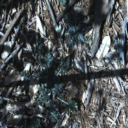

In [12]:

# 1. 라이브러리 불러오기
import zipfile
from pathlib import Path
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split

# 2. 이미지 압축 해제
if not Path("03_train").exists() or not Path("03_test").exists():
    with zipfile.ZipFile("03_images.zip", "r") as zip_ref:
        zip_ref.extractall(".")

# 3. 학습 및 테스트 데이터 불러오기
train_3 = pd.read_csv("03_train.csv")
test_3 = pd.read_csv("03_test_x.csv")

# 4. 이미지 경로 생성
train_3["image_path"] = train_3.apply(
    lambda row: str(Path("03_train") / row["label"] / row["file_name"]),
    axis=1
)

test_3["image_path"] = test_3["file_name"].apply(
    lambda name: str(Path("03_test") / name)
)

# 5. 이미지 파일 존재 여부 확인
missing_train_3 = sum(
    not Path(path).exists() for path in train_3["image_path"]
)
missing_test_3 = sum(
    not Path(path).exists() for path in test_3["image_path"]
)

assert missing_train_3 == 0
assert missing_test_3 == 0

# 6. 학습·검증 데이터 분리
X_train_3, X_valid_3, y_train_3, y_valid_3 = train_test_split(
    train_3["image_path"],
    train_3["label"],
    test_size=0.2,
    stratify=train_3["label"],
    random_state=42
)

# 7. 데이터 확인
sample_image_3 = Image.open(train_3["image_path"].iloc[0])

print("훈련 이미지:", len(train_3))
print("테스트 이미지:", len(test_3))
print("학습용:", len(X_train_3))
print("검증용:", len(X_valid_3))

print("\n클래스별 이미지 개수:")
print(train_3["label"].value_counts())

print("\n이미지 크기:", sample_image_3.size)
print("이미지 색상 모드:", sample_image_3.mode)

print("\n누락된 이미지:")
print("훈련:", missing_train_3)
print("테스트:", missing_test_3)

print("\n첫 번째 이미지:")
display(sample_image_3)


In [13]:

# 1. 라이브러리 불러오기
import numpy as np
import tensorflow as tf
from PIL import Image
from tensorflow.keras.applications import MobileNet
from tensorflow.keras.applications.mobilenet import preprocess_input
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# 2. 사전학습 MobileNet 특징 추출기 생성
feature_extractor_3 = MobileNet(
    input_shape=(224, 224, 3),
    alpha=0.25,
    include_top=False,
    weights="imagenet",
    pooling="avg"
)
feature_extractor_3.trainable = False

# 3. 이미지 특징 추출 함수
def extract_features_3(image_paths, batch_size=64):
    features = []

    for start in range(0, len(image_paths), batch_size):
        batch_paths = image_paths[start:start + batch_size]
        images = []

        for path in batch_paths:
            with Image.open(path) as img:
                img = img.convert("RGB").resize((224, 224))
                images.append(np.asarray(img, dtype=np.float32))

        batch_images = preprocess_input(np.stack(images))

        batch_features = feature_extractor_3.predict(
            batch_images, verbose=0
        )
        features.append(batch_features)

    return np.vstack(features)

# 4. 전체 훈련 이미지 특징 추출
features_3 = extract_features_3(train_3["image_path"].tolist())

# 5. 기존 학습·검증 분리 적용
features_train_3 = features_3[X_train_3.index.to_numpy()]
features_valid_3 = features_3[X_valid_3.index.to_numpy()]

# 6. 분류 모델 생성 및 학습
model_3 = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        C=1.0,
        max_iter=2000,
        random_state=42
    ))
])

model_3.fit(features_train_3, y_train_3)

# 7. 검증 정확도 평가
pred_valid_3 = model_3.predict(features_valid_3)
accuracy_3 = accuracy_score(y_valid_3, pred_valid_3)

print("추출된 전체 특징:", features_3.shape)
print("학습 특징:", features_train_3.shape)
print("검증 특징:", features_valid_3.shape)

print(f"\n검증 Accuracy: {accuracy_3:.4f}")
print(f"검증 정확도: {accuracy_3 * 100:.2f}%")
print("목표 정확도: 71.00%")
print(f"목표 달성: {'성공' if accuracy_3 >= 0.71 else '미달성'}")

print("\n클래스별 성능:")
print(classification_report(y_valid_3, pred_valid_3))


2108140/2108140 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
추출된 전체 특징: (1000, 256)
학습 특징: (800, 256)
검증 특징: (200, 256)

검증 Accuracy: 0.6950
검증 정확도: 69.50%
목표 정확도: 71.00%
목표 달성: 미달성

클래스별 성능:
              precision    recall  f1-score   support

chinee_apple       0.72      0.70      0.71        40
     lantana       0.68      0.68      0.68        40
 parkinsonia       0.75      0.75      0.75        40
  parthenium       0.63      0.72      0.67        40
 rubber_vine       0.71      0.62      0.67        40

    accuracy                           0.69       200
   macro avg       0.70      0.70      0.69       200
weighted avg       0.70      0.69      0.69       200



In [14]:

# 1. 라이브러리 불러오기
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# 2. 비교할 분류기 설정
candidates_3 = []

for c in [0.3, 1, 3, 10]:
    candidates_3.append((
        f"LogisticRegression C={c}",
        LogisticRegression(C=c, max_iter=3000, random_state=42)
    ))

for c in [1, 3, 10]:
    candidates_3.append((
        f"SVC RBF C={c}",
        SVC(kernel="rbf", C=c, gamma="scale")
    ))

# 3. 모델별 학습 및 검증
results_3 = []
best_accuracy_3 = -1
best_model_3 = None
best_name_3 = None

for name, classifier in candidates_3:
    candidate = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", classifier)
    ])

    candidate.fit(features_train_3, y_train_3)
    predictions = candidate.predict(features_valid_3)
    accuracy = accuracy_score(y_valid_3, predictions)

    results_3.append((name, accuracy))

    if accuracy > best_accuracy_3:
        best_accuracy_3 = accuracy
        best_model_3 = candidate
        best_name_3 = name

# 4. 결과 출력
print("모델별 검증 정확도:")
for name, accuracy in results_3:
    print(f"{name:28s}: {accuracy * 100:.2f}%")

print("\n최고 성능 모델:", best_name_3)
print(f"최고 검증 정확도: {best_accuracy_3 * 100:.2f}%")
print(f"목표 달성: {'성공' if best_accuracy_3 >= 0.71 else '미달성'}")


모델별 검증 정확도:
LogisticRegression C=0.3    : 69.00%
LogisticRegression C=1      : 69.50%
LogisticRegression C=3      : 69.50%
LogisticRegression C=10     : 68.50%
SVC RBF C=1                 : 77.00%
SVC RBF C=3                 : 75.00%
SVC RBF C=10                : 74.50%

최고 성능 모델: SVC RBF C=1
최고 검증 정확도: 77.00%
목표 달성: 성공


In [15]:

# 1. 라이브러리 불러오기
from sklearn.base import clone
import joblib
import os

# 2. 최고 성능 모델 설정 복사
final_model_3 = clone(best_model_3)

# 3. 전체 1,000장 특징으로 최종 학습
final_model_3.fit(features_3, train_3["label"])

# 4. 최종 분류 모델 저장
joblib.dump(final_model_3, "answer_3.pkl")

# 5. 저장 결과 확인
print("최종 학습 데이터:", features_3.shape)
print("최종 모델:", best_name_3)
print("분류 클래스:", final_model_3.classes_.tolist())
print("모델 파일:", "answer_3.pkl")
print("파일 크기:",
      round(os.path.getsize("answer_3.pkl") / 1024, 2), "KB")
print("모델 저장 완료")


최종 학습 데이터: (1000, 256)
최종 모델: SVC RBF C=1
분류 클래스: ['chinee_apple', 'lantana', 'parkinsonia', 'parthenium', 'rubber_vine']
모델 파일: answer_3.pkl
파일 크기: 1835.22 KB
모델 저장 완료


In [16]:

# 1. 라이브러리 불러오기
import joblib
import numpy as np
import pandas as pd
import os

# 2. 저장된 모델 불러오기
loaded_model_3 = joblib.load("answer_3.pkl")

# 3. 테스트 이미지 특징 추출
features_test_3 = extract_features_3(
    test_3["image_path"].tolist()
)

# 4. 저장 전후 예측 결과 비교
pred_before_3 = final_model_3.predict(features_test_3)
pred_after_3 = loaded_model_3.predict(features_test_3)

assert np.array_equal(pred_before_3, pred_after_3)
print("모델 복원 및 예측값 일치: PASS")

# 5. 원본 테스트 데이터에 정답 컬럼 추가
test_original_3 = pd.read_csv("03_test_x.csv")

answer_3 = test_original_3.copy()
answer_3["label"] = pred_after_3

# 6. 제출 CSV 저장
answer_3.to_csv("answer_3.csv", index=False)

# 7. 저장된 CSV 다시 읽어 검증
check_3 = pd.read_csv("answer_3.csv")

assert os.path.exists("answer_3.pkl")
assert os.path.exists("answer_3.csv")
assert features_test_3.shape == (250, 256)
assert len(check_3) == len(test_original_3) == 250
assert check_3.columns.tolist() == ["file_name", "label"]

pd.testing.assert_frame_equal(
    check_3.drop(columns=["label"]),
    test_original_3
)

assert check_3["label"].notna().all()
assert check_3["label"].isin(loaded_model_3.classes_).all()
assert np.array_equal(check_3["label"].to_numpy(), pred_after_3)

# 8. 최종 결과 출력
print("제출 파일 검증: PASS")
print("CSV 크기:", check_3.shape)
print("정답 컬럼:", check_3.columns[-1])

print("\n예측 클래스별 개수:")
print(check_3["label"].value_counts())

print("\n예측 결과 미리보기:")
print(check_3.head())

print("\n제출 파일: answer_3.pkl, answer_3.csv")


모델 복원 및 예측값 일치: PASS
제출 파일 검증: PASS
CSV 크기: (250, 2)
정답 컬럼: label

예측 클래스별 개수:
label
parthenium      54
lantana         54
rubber_vine     53
parkinsonia     48
chinee_apple    41
Name: count, dtype: int64

예측 결과 미리보기:
       file_name        label
0  test_0001.png  rubber_vine
1  test_0002.png   parthenium
2  test_0003.png   parthenium
3  test_0004.png  rubber_vine
4  test_0005.png   parthenium

제출 파일: answer_3.pkl, answer_3.csv


<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

압축을 풀고 폴더 구조(학습: 클래스별 폴더, 테스트: 한 폴더)를 확인합니다. 이미지를 같은 크기로 읽어 0~1 로 맞추고, 검증 데이터를 떼어 **작은 CNN**(또는 사전학습 모델 특징 + 분류기)을 학습합니다. 증강·Dropout·조기 종료로 과적합을 막고, 테스트는 `03_test_x.csv` 순서대로 예측하세요.

- 이 문항의 핵심: 주피터라이트에는 **MobileNet v1(alpha=0.25, 224×224, ImageNet) 가중치가 미리 들어 있습니다**. `MobileNet(input_shape=(224, 224, 3), alpha=0.25, include_top=False, weights='imagenet', pooling='avg')` 로 특징만 뽑고(가중치 고정), 그 특징으로 로지스틱 회귀 같은 분류기를 학습하세요. 다른 사전학습 모델(MobileNetV2·ResNet 등)은 브라우저에서 쓸 수 없습니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `pandas`, `joblib`, `Image`, `LogisticRegression`, `train_test_split`, `accuracy_score`, `MobileNet`, `preprocess_input`.

- 참고 문서: <https://joblib.readthedocs.io/en/stable/generated/joblib.dump.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html>
- 참고 문서: <https://keras.io/api/applications/mobilenet/>

</details>

<details><summary>힌트 3단계 (코드 구조) - 3번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____
import ____
import ____
import ____
from PIL import ____
from sklearn.linear_model import ____
from sklearn.model_selection import ____
from sklearn.metrics import ____
from tensorflow.keras.applications import ____
from tensorflow.keras.applications.mobilenet import ____

IMG_DIR = os.environ.get('____', '____')        # 압축을 풀 위치(브라우저판은 메모리 폴더 /tmp)
if not os.path.exists(os.path.join(IMG_DIR, '____')):
    zipfile.ZipFile('03_images.zip').extractall(IMG_DIR)
train = pd.read_csv('03_train.csv')
test = pd.read_csv('03_test_x.csv')

# ▷ 모델 구성(CNN 또는 사전학습 특징 추출)
# ▷ 학습(검증 데이터·조기 종료)
# ▷ 모델 파일 저장 — answer_N.pkl / .h5
# ▷ 테스트 데이터 예측(행 순서 그대로)
# ▷ 예측 CSV 저장 — answer_N.csv(테스트 열 + 마지막 정답 열)
```
- 제출 파일명: `answer_3.pkl`(모델) · `answer_3.csv`(예측)

</details>